# Experiment 1b: a deeper, honest evaluation

Experiment 1 found that the drift rule picks weeks no better than chance, and that a logistic regression scored AUC 0.48 on new students. This notebook asks the wider question: under fair rules, how well can phone data pick out a week with a high PHQ-2?

This is the second version. An independent review of the first version found that its phone features included up to three days after the PHQ-2 answer, that its "one-tap check-in" used every earlier check-in, and that the StudentLife call and text counts were logger records. Framing 1b now uses only phone days before the answer, a single check-in has its own row, and StudentLife counts real call events. `results/exp1b/results.md` lists every change.

All the work happens in `experiments/exp1b_deeper.py`. Run it first (`.venv/bin/python experiments/exp1b_deeper.py`). It writes `results/exp1b/results.json`, which this notebook reads. The notebook then repeats two quick checks live from the cached tables and draws the summary chart.

**Data terms.** The College Experience Study (Dartmouth) is licensed CC BY-NC-SA 4.0 for academic use. Nothing here shows a student id or a per-student row. Every table and chart is an aggregate over students.

**How to read the numbers.** AUC is the chance that a random high week gets a higher risk score than a random ordinary week. 0.5 is a coin flip and 1.0 is perfect. PR-AUC starts at the base rate (about 0.13 here) for a model that knows nothing. Sensitivity at 80% specificity is read off the test ROC curve and interpolated, so it describes the curve and is not a tested threshold. Every interval is a 95% interval from resampling students; it does not include the step of choosing among models, so every model's result is shown.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "experiments"))
import exp1b_deeper as ex

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)

# Light chart style, the same as notebooks 01 and 02
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8f8e88"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10, "legend.frameon": False,
})

res = json.loads((REPO / "results" / "exp1b" / "results.json").read_text())
print(f"Results generated {res['generated']}, run took {res['runtime_seconds']:.0f} seconds.")
pd.Series(res["data"], name="value").to_frame()

Results generated 2026-11-14, run took 282 seconds.


,value
students,213.0000
labelled_weeks,16886.0000
base_rate,0.1286
daily_features,171.0000
passive_features,686.0000
checkin_features,19.0000
before_answer_weeks,16684.0000
before_answer_students,213.0000
before_answer_base_rate,0.1289
before_answer_features,686.0000


## 1. Every framing

One row per model or baseline. "model" rows use phone data, check-ins or both. "with history" rows add earlier PHQ-2 answers. "nested" rows choose the model inside each training part. "baseline" rows are the yardsticks: no information, and earlier PHQ-2 answers alone. "control" rows are the same pipeline trained on shuffled labels, which must land near 0.5. The "note" row is the first, flawed StudentLife version, kept for the record.

In [2]:
def ci(x):
    return f"{x[0]:.2f} to {x[1]:.2f}"

tab = pd.DataFrame(res["rows"])
show = tab.assign(auc_95=tab["auc_ci"].map(ci))[
    ["framing", "model", "kind", "auc", "auc_95", "pr_auc", "sens_at_80_spec", "base_rate", "n_students", "n_rows"]]
show.round(3)

,framing,model,kind,auc,auc_95,pr_auc,sens_at_80_spec,base_rate,n_students,n_rows
0,"1a. Across students, same-week association",Logistic regression,model,0.571,0.51 to 0.63,0.170,0.304,0.129,213,16886
1,"1a. Across students, same-week association",Gradient boosting (HistGB),model,0.569,0.52 to 0.62,0.163,0.275,0.129,213,16886
2,"1a. Across students, same-week association",Random forest,model,0.578,0.52 to 0.63,0.162,0.284,0.129,213,16886
3,"1a. Across students, same-week association","Gradient boosting, own-past z-scores only",variant,0.518,0.47 to 0.57,0.135,0.210,0.129,213,16886
4,"1a. Across students, same-week association","Logistic regression, scored on the rows 1b also has",variant,0.569,0.51 to 0.63,0.170,0.303,0.129,213,16581
...,...,...,...,...,...,...,...,...,...,...
102,"7b. StudentLife 2013 (external), PHQ-9 >= 5",Term average: Logistic regression,model,0.596,0.41 to 0.78,0.620,0.410,0.500,38,38
103,"7b. StudentLife 2013 (external), PHQ-9 >= 5",Term average: Random forest,model,0.560,0.37 to 0.76,0.570,0.263,0.500,38,38
104,"7b. StudentLife 2013 (external), PHQ-9 >= 5",Base rate (no information),baseline,0.500,0.50 to 0.50,0.500,0.200,0.500,38,38
105,"7b. StudentLife 2013 (external), PHQ-9 >= 5",PHQ-9 at the start of term alone,baseline,0.895,0.78 to 0.97,0.884,0.810,0.500,38,38


## 2. Leakage checks

Each check runs in code inside the script. A check that failed would show `False` here.

In [3]:
chk = pd.DataFrame([{"check": k, "passed": v["passed"], "what": v["what"]} for k, v in res["leakage_checks"].items()])
chk

,check,passed,what
0,student_split,True,Every cross-validation fold is checked in code: no student is in both the training and...
1,past_only_features,True,Every week after a cut-off was replaced with noise. The z-scores and last-week values ...
2,checkin_before_label,True,The latest check-in answer used for a week is always from an earlier day than that wee...
3,earlier_phq2_before_monday,True,"Every earlier PHQ-2 answer used as a feature is dated before Monday of the week, so at..."
4,label_shuffle,True,The same pipeline run on shuffled labels must score near 0.5: within 0.47 to 0.53 on t...
5,phone_before_answer,True,"In framings 1b, 2, 4 and 5 every phone day used, including the personal baseline weeks..."
6,personal_14_day_separation,True,In the personal models every test answer comes 14 or more days after the last training...
7,separated_inputs_before_recall_window,True,In framing 5b every PHQ-2 and check-in input is dated 14 or more days before the answe...
8,no_self_report_in_passive,True,"Every passive feature set is checked in code for PHQ, label, check-in or history columns."
9,transforms_inside_folds,True,"Scaling, imputation and every model are fit on the training part of each fold only. Pe..."


## 3. What a near-perfect number is made of

These are built wrong on purpose. Each one is a common way to get a number close to 1.0 from this data. The right-hand column is the same idea done fairly.

In [4]:
lk = pd.DataFrame([{"leak": l["name"], "AUC with the leak": l["leaky"]["auc"],
                    "fair version": l["fixed_name"], "AUC fair": l["fixed"]["auc"], "cause": l["cause"]}
                   for l in res["leak_demos"]])
lk.round(3)

,leak,AUC with the leak,fair version,AUC fair,cause
0,Anxiety items from the label's own survey,0.809,Same-week phone plus check-in history (logistic),0.739,"PHQ-4 items 1 and 2 are answered on the same screen, seconds before the two items that..."
1,The PHQ-4 total from the label's own survey,0.980,Most recent PHQ-2 before Monday,0.877,"The PHQ-4 total contains the two PHQ-2 items, so it is the label plus noise."
2,Each student's average PHQ-2 over all their weeks,0.882,Average of earlier answers only,0.876,The average includes this week's answer and every later answer.
3,"Weeks split at random, so each student sits in train and test",0.821,Split by student,0.569,"The model learns each student's usual phone pattern and their usual mood, then meets t..."
4,"Random week split, with check-ins and earlier PHQ-2 answers as features",0.914,"Same features, split by student",0.905,"Same as above, with mood answers added. The model meets students it already knows."
5,z-scores normalised with the student's future weeks,0.545,Own-past z-scores only,0.518,Each week is compared with a mean and spread that include later weeks.
6,Depresjon days split at random,0.833,"Per day, split by person",0.644,"Days from the same person land in train and test, so the model recognises the person."


## 4. Two checks repeated live

The script caches its weekly table. Here we rebuild two numbers from that cache: the most recent PHQ-2 before Monday on framing 1a's weeks, and the PHQ-4 total leak. They should match the JSON.

In [5]:
W, meta = ex.build_tables(verbose=False)
D = ex.week_rows(W)
y, g = D["label"].to_numpy(), D["sid"].to_numpy()
live_prev = ex.evaluate(y, ex.prior_score(D["prev_phq2"].to_numpy(), float(np.nanmedian(D["prev_phq2"]))), g, n_boot=200)
live_leak = ex.evaluate(y, D["leak_same_survey_phq4_score"].to_numpy(float), g, n_boot=200, within=False)
json_prev = next(r for r in res["rows"] if r["framing"] == ex.F1A and r["model"] == ex.RECENT_PHQ)
json_leak = next(l for l in res["leak_demos"] if l["name"].startswith("The PHQ-4 total"))
pd.DataFrame({"live": [live_prev["auc"], live_leak["auc"]], "results.json": [json_prev["auc"], json_leak["leaky"]["auc"]]},
             index=["Most recent PHQ-2 before Monday", "PHQ-4 total from the label's own survey (a leak)"]).round(3)

,live,results.json
Most recent PHQ-2 before Monday,0.877,0.877
PHQ-4 total from the label's own survey (a leak),0.980,0.980


## 5. Summary chart

AUC with its 95% interval for each framing and every model. Blue rows use passive data only (phone, or a wrist actigraph for Depresjon). Orange rows also use the student's own answers: a check-in, earlier PHQ-2 answers, or a personal intercept learned from them. Gray rows are baselines and shuffled-label controls. Personal models are shown for 16 training weeks; the 8-week rows are in the table above.

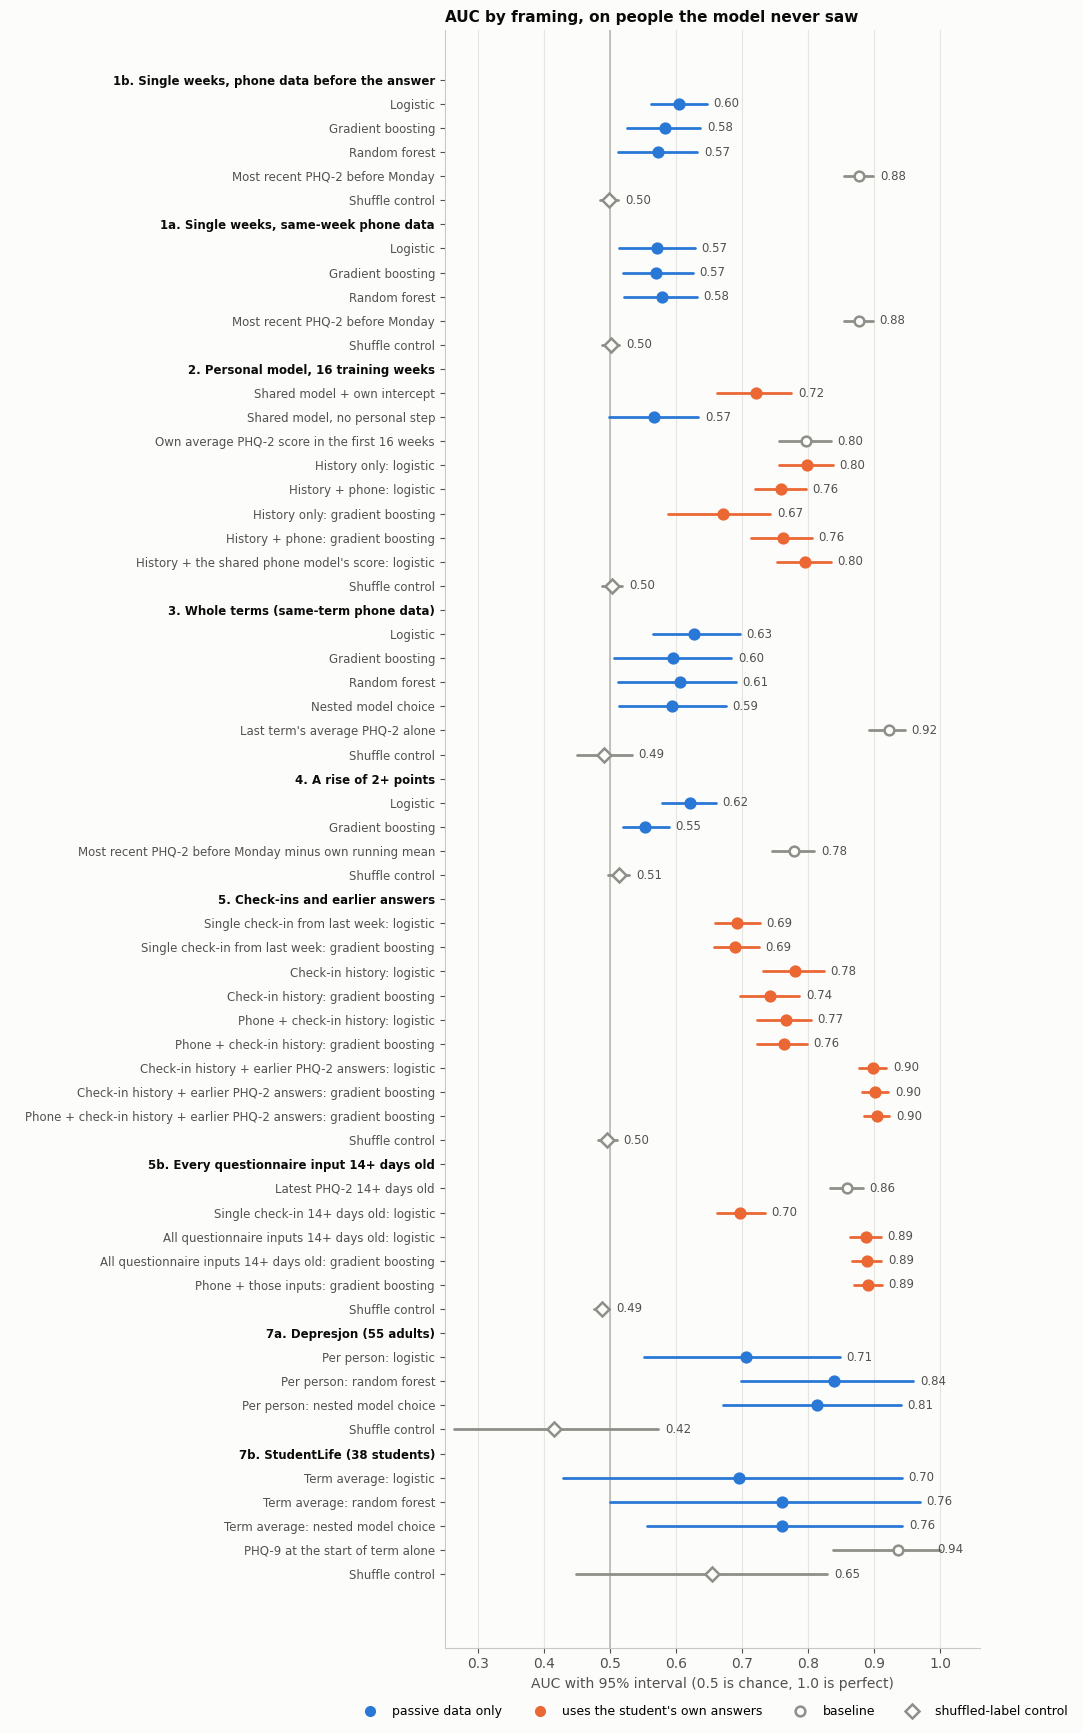

In [6]:
SHORT_FRAMING = {
    ex.F1B: "1b. Single weeks, phone data before the answer",
    ex.F1A: "1a. Single weeks, same-week phone data",
    f"{ex.F2}, first 16 eligible weeks": "2. Personal model, 16 training weeks",
    ex.F3: "3. Whole terms (same-term phone data)",
    ex.F4: "4. A rise of 2+ points",
    ex.F5: "5. Check-ins and earlier answers",
    ex.F5S: "5b. Every questionnaire input 14+ days old",
    ex.F7D: "7a. Depresjon (55 adults)",
    f"{ex.F7S}, PHQ-9 >= 10": "7b. StudentLife (38 students)",
}
SHORT_MODEL = [("Gradient boosting (HistGB)", "gradient boosting"), ("Logistic regression", "logistic"),
               ("Random forest", "random forest"),
               ("Label-shuffle control (pooled + own intercept)", "shuffle control"),
               ("Pooled gradient boosting", "shared model"), ("Gradient boosting", "gradient boosting"),
               ("History only (own average and share high)", "History only"),
               ("History plus phone data before the answer", "History + phone"),
               ("Single last-week check-in (latest answer)", "Single check-in from last week"),
               ("Latest PHQ-2 answered 14 or more days before, alone", "Latest PHQ-2 14+ days old"),
               ("All questionnaire inputs 14 or more days before", "All questionnaire inputs 14+ days old"),
               ("Single check-in 14 or more days before", "Single check-in 14+ days old"),
               ("Phone before the answer plus those inputs", "Phone + those inputs"),
               ("Phone before the answer plus ", "Phone + "), (" plus ", " + "),
               ("nested choice among the three models", "nested model choice"),
               ("Nested choice among the three models", "Nested model choice"),
               ("nested choice between the two models", "nested model choice")]

def short_model(m):
    m = m.replace("Label-shuffle control (Logistic regression)", "shuffle control")
    for a, b in SHORT_MODEL:
        m = m.replace(a, b)
    return m[0].upper() + m[1:]

order = [r for r in res["summary_rows"] if r["chart"]]
# One header line per framing, then its rows
entries, prev = [], None
for r in order:
    if r["framing"] != prev:
        entries.append((SHORT_FRAMING.get(r["framing"], r["framing"]), None))
        prev = r["framing"]
    entries.append(("    " + short_model(r["model"]), r))
colors = {"phone": BLUE, "answers": ORANGE, "baseline": GRAY, "control": GRAY}
fig, ax = plt.subplots(figsize=(10, 0.25 * len(entries) + 1.6))
ax.axvline(0.5, color="#b9b8b2", lw=1.2, zorder=1)
for i, (lab, r) in enumerate(entries):
    if r is None:
        continue
    c = colors[r["group"]]
    lo, hi = r["auc_ci"]
    ax.plot([lo, hi], [i, i], color=c, lw=2, solid_capstyle="round", zorder=2)
    filled = r["group"] in ("phone", "answers")
    ax.plot(r["auc"], i, "o" if r["group"] != "control" else "D", ms=7, mfc=c if filled else SURFACE,
            mec=c, mew=1.8, zorder=3)
    ax.text(min(hi, 0.985) + 0.01, i, f"{r['auc']:.2f}", va="center", ha="left", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(entries)))
ax.set_yticklabels([lab for lab, _ in entries], fontsize=8.5)
for tick, (lab, r) in zip(ax.get_yticklabels(), entries):
    if r is None:
        tick.set_fontweight("bold")
        tick.set_color(INK)
order = entries
ax.invert_yaxis()
ax.set_xlim(0.25, 1.06)
ax.set_xticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_xlabel("AUC with 95% interval (0.5 is chance, 1.0 is perfect)")
ax.set_title("AUC by framing, on people the model never saw")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=BLUE, mec=BLUE, label="passive data only"),
           Line2D([], [], marker="o", ls="", ms=7, mfc=ORANGE, mec=ORANGE, label="uses the student's own answers"),
           Line2D([], [], marker="o", ls="", ms=7, mfc=SURFACE, mec=GRAY, mew=1.8, label="baseline"),
           Line2D([], [], marker="D", ls="", ms=7, mfc=SURFACE, mec=GRAY, mew=1.8, label="shuffled-label control")]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.045 * 40 / len(order)), ncol=4, fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6. What this shows

Phone data recorded before the answer sits a little above chance on students the models never saw, and the same-week version does no better. Most of the extra accuracy in the orange rows comes from the student's own answers: a single check-in from the week before beats every phone-only model, and earlier PHQ-2 answers beat that. The honest rows near or above 0.90 all use earlier PHQ answers, and results.md explains why we read them as persistence. The leaks in section 3 show how easy it is to report a number near 1.0 by accident. The full write-up is in `results/exp1b/results.md`.